# Xenium Mouse Brain Pseudo-Batch Alignment Prototype

This notebook is a fast prototype for a splat-based alignment / batch-correction idea on the 10x Xenium mouse-brain public subset.

It does **not** assume the shipped subset has an explicit true batch label. Instead it creates two pseudo-experiments from the same real tissue:

- source sample: original Xenium subset
- target sample: affine-transformed copy with injected gene-profile drift

The experiment then asks whether independently trained splat fields can be used to recover:

1. the geometric transform
2. the expression drift

This sits conceptually between the multislice registration task and the PDAC transfer task.


In [1]:
from pathlib import Path
import math
import random
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / "pyproject.toml").exists()
        and (PROJECT_ROOT / "spatsplat").is_dir()
        and (PROJECT_ROOT / "paper").is_dir()
    ):
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise RuntimeError("Could not find the spatsplat project root")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from spatsplat import (
    AmplitudeSplatField,
    DataConfig,
    SplatConfig,
    build_cell_only_targets,
    compute_splat_weights,
    composition_cosine_loss,
    create_amplitude_splat_optimizer,
    farthest_point_sample_indices,
    log_total_count_loss,
    mae_count_loss,
    GeneProfileAutoencoder,
    evaluate_profile_autoencoder,
    train_profile_autoencoder,
)
from paper.data_loaders.xenium_mouse_brain import load_tiny_xenium_dataset


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
display_sig_digits = 4


def format_scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if np.isnan(value) or np.isinf(value):
            return value
        return float(f'{value:.{display_sig_digits}g}')
    return value


def format_for_display(obj):
    if isinstance(obj, dict):
        return {k: format_for_display(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [format_for_display(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(format_for_display(v) for v in obj)
    return format_scalar(obj)


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)




device: cuda


In [2]:
random_seed = 7
set_seed(random_seed)

data_cfg = DataConfig(bin_size=64, mask_grid_size=128, qv_threshold=20, cell_mask_min_radius=1.0)
splat_cfg = SplatConfig(
    num_splats=256,
    latent_dim=32,
    hidden_dim=128,
    init_log_scale=-4.5,
    kernel_sharpness=0.5,
)

max_cells = 12000
shared_ae_hidden_dim = 128
shared_ae_latent_dim = 32
shared_ae_lr = 1e-3
shared_ae_epochs = 120
shared_ae_batch_size = 1024

splat_epochs = 250
splat_batch_size = 1024
splat_means_lr = 5e-3
splat_log_scales_lr = 2e-3
splat_rotation_lr = 1e-3
splat_opacity_lr = 1e-3
splat_latents_lr = 2e-3
splat_decoder_lr = 1e-4
splat_amplitude_lr = 2e-3
splat_log_theta_lr = 1e-4

composition_loss_weight = 1.0
total_count_loss_weight = 0.1
mae_refine_fraction = 0.25
mae_refine_weight = 1.0

transform_angle_deg = 6.0
transform_scale_xy = (1.04, 0.96)
transform_translation_xy = (0.02, -0.03)

local_warp_amplitude = 0.035
local_warp_frequency = 2.5
local_warp_phase = 0.4
partial_overlap_xmin = 0.08
partial_overlap_ymax = 0.94

base_drift_top_gene_pool = 96
base_drift_num_genes = 0
base_drift_bias_range = 0.0
region_drift_num_genes = 64
region_drift_bias_range = 2.5
region_drift_center_a = (0.62, 0.38)
region_drift_center_b = (0.28, 0.68)
region_drift_radius = 0.22
region_drift_sharpness = 22.0
drift_library_scale = 1.0

dropout_region_center = (0.3, 0.72)
dropout_region_radius = 0.12
dropout_keep_fraction = 0.25

match_cosine_threshold = 0.7




## Load The Xenium Mouse-Brain Subset

This uses the same public `tiny_xenium` subset already used in the core splat-field notebooks. The goal here is not new data engineering. It is a fast prototype for splat-based geometry plus program alignment.


In [3]:
loaded = load_tiny_xenium_dataset(config=data_cfg)
built = build_cell_only_targets(loaded, config=data_cfg)

gene_names = np.asarray(loaded.gene_list, dtype=object)
gene_to_id = loaded.gene_to_id

all_xy = built.cell_features.to(device)
all_spans = built.cell_spans.to(device)
all_counts = built.cell_targets.to(device)

set_seed(random_seed + 1)
perm = torch.randperm(len(all_xy), device=device)
keep_idx = perm[:min(max_cells, len(all_xy))]

source_xy = all_xy[keep_idx]
source_spans = all_spans[keep_idx]
source_counts = all_counts[keep_idx]
source_profiles = source_counts / source_counts.sum(dim=1, keepdim=True).clamp_min(1.0)
source_totals = source_counts.sum(dim=1, keepdim=True)

summary = {
    'dataset': 'tiny_xenium',
    'n_cells_total': int(len(all_xy)),
    'n_cells_used': int(len(source_xy)),
    'n_genes': int(source_counts.shape[1]),
    'mean_total_count': float(source_totals.mean().item()),
    'median_total_count': float(source_totals.median().item()),
}
print(format_for_display(summary))



{'dataset': 'tiny_xenium', 'n_cells_total': 36602, 'n_cells_used': 12000, 'n_genes': 248, 'mean_total_count': 244.8, 'median_total_count': 208.0}


In [4]:
def apply_affine_xy(xy: torch.Tensor, angle_deg: float, scale_xy: tuple[float, float], translation_xy: tuple[float, float]):
    theta = math.radians(angle_deg)
    rot = torch.tensor(
        [[math.cos(theta), -math.sin(theta)], [math.sin(theta), math.cos(theta)]],
        dtype=xy.dtype,
        device=xy.device,
    )
    scale = torch.tensor([[scale_xy[0], 0.0], [0.0, scale_xy[1]]], dtype=xy.dtype, device=xy.device)
    linear = rot @ scale
    center = torch.tensor([0.5, 0.5], dtype=xy.dtype, device=xy.device)
    translation = torch.tensor(translation_xy, dtype=xy.dtype, device=xy.device)
    warped = (xy - center) @ linear.T + center + translation
    offset = center - center @ linear.T + translation
    return warped, linear, offset


def apply_local_warp(xy: torch.Tensor, amplitude: float, frequency: float, phase: float):
    x = xy[:, 0]
    y = xy[:, 1]
    dx = amplitude * torch.sin(2.0 * math.pi * frequency * y + phase)
    dy = amplitude * torch.cos(2.0 * math.pi * frequency * x - phase)
    return xy + torch.stack([dx, dy], dim=1)


def radial_soft_mask(xy: torch.Tensor, center: tuple[float, float], radius: float, sharpness: float):
    center_t = torch.tensor(center, dtype=xy.dtype, device=xy.device)
    dist = torch.norm(xy - center_t, dim=1)
    return torch.sigmoid((radius - dist) * sharpness)


source_xy_display = source_xy.detach().clone()
affine_target_xy, true_linear, true_offset = apply_affine_xy(
    source_xy,
    angle_deg=transform_angle_deg,
    scale_xy=transform_scale_xy,
    translation_xy=transform_translation_xy,
)
target_xy_all = apply_local_warp(
    affine_target_xy,
    amplitude=local_warp_amplitude,
    frequency=local_warp_frequency,
    phase=local_warp_phase,
)

in_bounds = ((target_xy_all >= 0.0) & (target_xy_all <= 1.0)).all(dim=1)
partial_overlap_mask = (target_xy_all[:, 0] >= partial_overlap_xmin) & (target_xy_all[:, 1] <= partial_overlap_ymax)
keep_mask = in_bounds & partial_overlap_mask

source_xy = source_xy[keep_mask]
source_spans = source_spans[keep_mask]
source_counts = source_counts[keep_mask]
source_profiles = source_profiles[keep_mask]
source_totals = source_totals[keep_mask]
target_xy = target_xy_all[keep_mask]

set_seed(random_seed + 2)
mean_gene_mass = source_counts.sum(dim=0)
top_pool = torch.topk(mean_gene_mass, k=min(base_drift_top_gene_pool, source_counts.shape[1])).indices
shuffle = top_pool[torch.randperm(len(top_pool), device=device)]
base_gene_idx = shuffle[:min(base_drift_num_genes, len(shuffle))]
remaining = shuffle[min(base_drift_num_genes, len(shuffle)):]
region_gene_idx = remaining[:min(region_drift_num_genes, len(remaining))]

base_log_bias = torch.zeros(source_counts.shape[1], dtype=source_counts.dtype, device=device)
base_bias_values = torch.linspace(-base_drift_bias_range, base_drift_bias_range, steps=len(base_gene_idx), device=device)
base_log_bias[base_gene_idx] = base_bias_values

region_log_bias_a = torch.zeros(source_counts.shape[1], dtype=source_counts.dtype, device=device)
region_log_bias_b = torch.zeros(source_counts.shape[1], dtype=source_counts.dtype, device=device)
region_gene_idx_a = region_gene_idx[0::2]
region_gene_idx_b = region_gene_idx[1::2]
if len(region_gene_idx_a) > 0:
    region_bias_values_a = torch.linspace(-region_drift_bias_range, region_drift_bias_range, steps=len(region_gene_idx_a), device=device)
    region_log_bias_a[region_gene_idx_a] = region_bias_values_a
if len(region_gene_idx_b) > 0:
    region_bias_values_b = torch.linspace(region_drift_bias_range, -region_drift_bias_range, steps=len(region_gene_idx_b), device=device)
    region_log_bias_b[region_gene_idx_b] = region_bias_values_b

region_weight_a = radial_soft_mask(target_xy, region_drift_center_a, region_drift_radius, region_drift_sharpness).unsqueeze(1)
region_weight_b = radial_soft_mask(target_xy, region_drift_center_b, region_drift_radius, region_drift_sharpness).unsqueeze(1)
combined_log_bias = (
    base_log_bias.unsqueeze(0)
    + region_weight_a * region_log_bias_a.unsqueeze(0)
    + region_weight_b * region_log_bias_b.unsqueeze(0)
)
biased_profiles = source_profiles * torch.exp(combined_log_bias)
biased_profiles = biased_profiles / biased_profiles.sum(dim=1, keepdim=True).clamp_min(1e-8)

dropout_weight = radial_soft_mask(target_xy, dropout_region_center, dropout_region_radius, region_drift_sharpness)
keep_prob = 1.0 - dropout_weight * (1.0 - dropout_keep_fraction)
dropout_scale = keep_prob.unsqueeze(1)

target_counts = biased_profiles * source_totals * drift_library_scale * dropout_scale

true_log_bias = combined_log_bias.mean(dim=0)
base_drift_gene_names = [str(gene_names[int(i)]) for i in base_gene_idx.detach().cpu().tolist()]
region_drift_gene_names_a = [str(gene_names[int(i)]) for i in region_gene_idx_a.detach().cpu().tolist()]
region_drift_gene_names_b = [str(gene_names[int(i)]) for i in region_gene_idx_b.detach().cpu().tolist()]
pseudobatch_summary = {
    'n_paired_cells': int(len(source_xy)),
    'transform_angle_deg': float(transform_angle_deg),
    'transform_scale_xy': [float(x) for x in transform_scale_xy],
    'transform_translation_xy': [float(x) for x in transform_translation_xy],
    'local_warp_amplitude': float(local_warp_amplitude),
    'partial_overlap_fraction_kept': float(keep_mask.float().mean().item()),
    'n_base_drift_genes': int(len(base_gene_idx)),
    'n_region_a_drift_genes': int(len(region_gene_idx_a)),
    'n_region_b_drift_genes': int(len(region_gene_idx_b)),
    'base_drift_genes': base_drift_gene_names[:12],
    'region_a_drift_genes': region_drift_gene_names_a[:12],
    'region_b_drift_genes': region_drift_gene_names_b[:12],
    'mean_abs_local_log_bias': float(combined_log_bias.abs().mean().item()),
}
print(format_for_display(pseudobatch_summary))




{'n_paired_cells': 11024, 'transform_angle_deg': 6.0, 'transform_scale_xy': [1.04, 0.96], 'transform_translation_xy': [0.02, -0.03], 'local_warp_amplitude': 0.035, 'partial_overlap_fraction_kept': 0.9187, 'n_base_drift_genes': 0, 'n_region_a_drift_genes': 32, 'n_region_b_drift_genes': 32, 'base_drift_genes': [], 'region_a_drift_genes': ['Zfp536', 'Gng12', 'Clmn', 'Rab3b', 'Gad2', 'Cabp7', 'Prdm8', 'Nwd2', 'Bhlhe40', 'Necab1', 'Grik3', 'Slc17a6'], 'region_b_drift_genes': ['Ly6a', 'Aqp4', 'Fn1', 'Rims3', 'Pdzrn3', 'Ntsr2', 'Fhod3', 'Cpne4', 'Pde7b', 'Gfap', 'Tmem132d', 'Neto2'], 'mean_abs_local_log_bias': 0.07664}


## Pseudo-Batch Geometry And Drift

Batch B is the same tissue after a mild affine perturbation and a gene-profile drift. This keeps the biology fixed while giving the splat alignment procedure something real to recover.


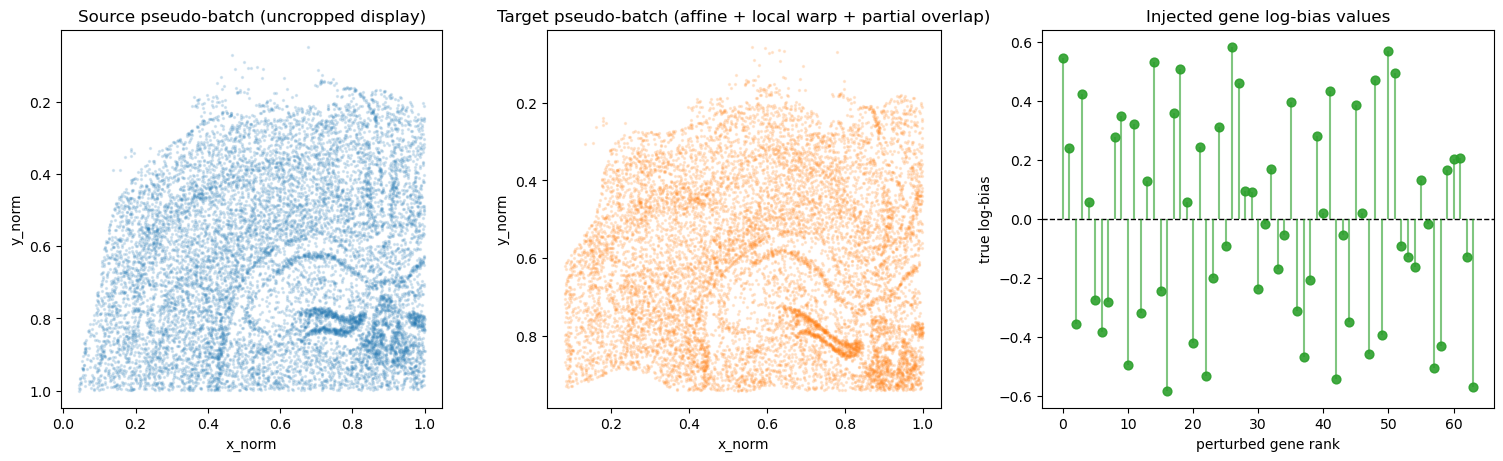

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

axes[0].scatter(source_xy_display[:, 0].detach().cpu().numpy(), source_xy_display[:, 1].detach().cpu().numpy(), s=2, alpha=0.15)
axes[0].invert_yaxis()
axes[0].set_aspect('equal')
axes[0].set_title('Source pseudo-batch (uncropped display)')
axes[0].set_xlabel('x_norm')
axes[0].set_ylabel('y_norm')

axes[1].scatter(target_xy[:, 0].detach().cpu().numpy(), target_xy[:, 1].detach().cpu().numpy(), s=2, alpha=0.15, color='tab:orange')
axes[1].invert_yaxis()
axes[1].set_aspect('equal')
axes[1].set_title('Target pseudo-batch (affine + local warp + partial overlap)')
axes[1].set_xlabel('x_norm')
axes[1].set_ylabel('y_norm')

true_bias_np = true_log_bias.detach().cpu().numpy()
nonzero_bias = true_bias_np[true_bias_np != 0]
axes[2].axhline(0.0, color='black', linestyle='--', linewidth=1)
axes[2].scatter(np.arange(len(nonzero_bias)), nonzero_bias, s=40, color='tab:green', alpha=0.9)
axes[2].vlines(np.arange(len(nonzero_bias)), 0.0, nonzero_bias, color='tab:green', alpha=0.6, linewidth=1.5)
axes[2].set_title('Injected gene log-bias values')
axes[2].set_xlabel('perturbed gene rank')
axes[2].set_ylabel('true log-bias')

plt.show()





## Source-Only Profile Autoencoder

Train one profile autoencoder on the source pseudo-batch only, then use that source-derived latent/program basis to initialize both splat fields. This is a stricter batch-correction setup because the AE does not see the target drift during training.



In [6]:
source_only_profiles = source_profiles
source_perm = torch.randperm(len(source_only_profiles), device=device)
train_end = int(0.8 * len(source_perm))
val_end = int(0.9 * len(source_perm))
source_only_split_idx = {
    'train': source_perm[:train_end],
    'val': source_perm[train_end:val_end],
    'test': source_perm[val_end:],
}


In [7]:
set_seed(random_seed + 3)
source_profile_autoencoder = GeneProfileAutoencoder(
    num_genes=source_only_profiles.shape[1],
    hidden_dim=shared_ae_hidden_dim,
    latent_dim=shared_ae_latent_dim,
).to(device)

opt = torch.optim.Adam(source_profile_autoencoder.parameters(), lr=shared_ae_lr)
ae_history = train_profile_autoencoder(
    source_profile_autoencoder,
    source_only_profiles,
    source_only_split_idx['train'],
    source_only_split_idx['val'],
    epochs=shared_ae_epochs,
    batch_size=shared_ae_batch_size,
    optimizer=opt,
    max_grad_norm=5.0,
)

ae_summary = {
    split: evaluate_profile_autoencoder(source_profile_autoencoder, source_only_profiles, idx, batch_size=shared_ae_batch_size)
    for split, idx in source_only_split_idx.items()
}
print('Source-only AE summary')
print(format_for_display(ae_summary))



Source-only AE summary
{'train': {'loss': 4.312, 'mae': 0.002783, 'cosine': 0.8669, 'n': 8819}, 'val': {'loss': 4.27, 'mae': 0.002879, 'cosine': 0.8534, 'n': 1102}, 'test': {'loss': 4.319, 'mae': 0.002872, 'cosine': 0.8584, 'n': 1103}}


## Independent Splat Fields

Train one source splat field and one target splat field with shared AE initialization and independent geometry. This mirrors the registration setup more than the PDAC transfer setup.


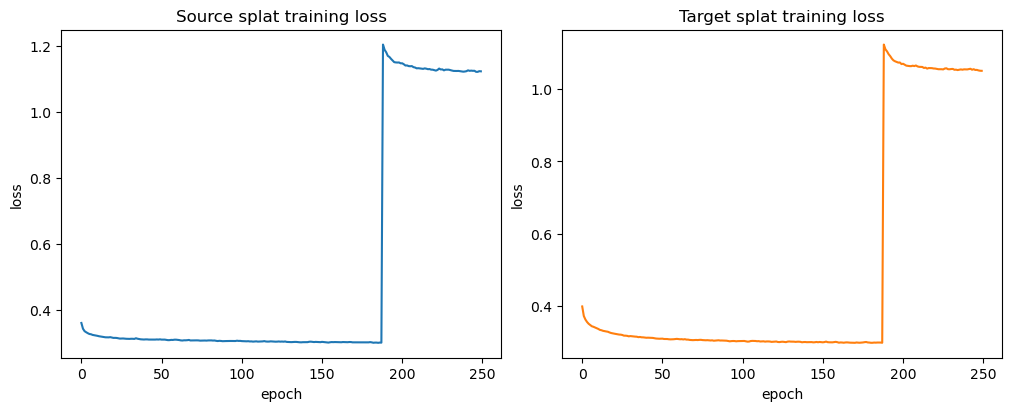

In [8]:
source_bundle = {
    'xy': source_xy,
    'counts': source_counts,
    'profiles': source_profiles,
    'totals': source_totals,
}
target_bundle = {
    'xy': target_xy,
    'counts': target_counts,
    'profiles': target_counts / target_counts.sum(dim=1, keepdim=True).clamp_min(1.0),
    'totals': target_counts.sum(dim=1, keepdim=True),
}


def init_splat_model(section_xy: torch.Tensor, section_profiles: torch.Tensor, section_total_counts: torch.Tensor, *, num_splats: int):
    with torch.no_grad():
        seed_idx = farthest_point_sample_indices(section_xy, num_splats)
        seed_xy = section_xy[seed_idx]
        pairwise_dist = torch.cdist(seed_xy, section_xy)
        neighbor_k = min(16, section_xy.shape[0])
        _, neighbor_idx = torch.topk(pairwise_dist, k=neighbor_k, largest=False, dim=1)
        avg_profiles = section_profiles[neighbor_idx].mean(dim=1)
        avg_profiles = avg_profiles / avg_profiles.sum(dim=1, keepdim=True).clamp_min(1e-8)
        avg_totals = section_total_counts[neighbor_idx].mean(dim=1)
        encoded_seed_latents = source_profile_autoencoder.encoder(avg_profiles)

    model = AmplitudeSplatField(
        num_splats=num_splats,
        latent_dim=splat_cfg.latent_dim,
        hidden_dim=splat_cfg.hidden_dim,
        num_genes=section_profiles.shape[1],
        init_log_scale=splat_cfg.init_log_scale,
        kernel_sharpness=splat_cfg.kernel_sharpness,
        init_log_amplitude=0.0,
    ).to(device)

    with torch.no_grad():
        model.means.copy_(seed_xy)
        model.latents.copy_(encoded_seed_latents)
        model.log_amplitudes.copy_(avg_totals.clamp_min(1.0).log())
        model.rotation.zero_()
        model.opacity_logits.zero_()
        model.decoder.load_state_dict(source_profile_autoencoder.decoder.state_dict())
    return model


def clone_splat_model(model):
    cloned = AmplitudeSplatField(
        num_splats=model.num_splats,
        latent_dim=model.latent_dim,
        hidden_dim=model.hidden_dim,
        num_genes=model.num_genes,
        init_log_scale=model.init_log_scale,
        kernel_sharpness=model.kernel_sharpness,
        init_log_amplitude=float(model.log_amplitudes.detach().mean().item()),
    ).to(device)
    cloned.load_state_dict({k: v.detach().clone() for k, v in model.state_dict().items()})
    return cloned


def train_splat_model(initial_model, bundle, *, seed: int):
    set_seed(seed)
    model = clone_splat_model(initial_model)
    optimizer = create_amplitude_splat_optimizer(
        model,
        means_lr=splat_means_lr,
        log_scales_lr=splat_log_scales_lr,
        rotation_lr=splat_rotation_lr,
        opacity_lr=splat_opacity_lr,
        latents_lr=splat_latents_lr,
        decoder_lr=splat_decoder_lr,
        amplitude_lr=splat_amplitude_lr,
        log_theta_lr=splat_log_theta_lr,
    )
    xy = bundle['xy']
    counts = bundle['counts']
    perm_base = torch.arange(len(xy), device=device)
    history = {'train_loss': []}
    mae_refine_start = max(0, int(round((1.0 - mae_refine_fraction) * splat_epochs)))

    for epoch in range(splat_epochs):
        model.train()
        perm = perm_base[torch.randperm(len(perm_base), device=device)]
        mae_refine_active = epoch >= mae_refine_start
        running_loss = 0.0
        steps = 0
        for start in range(0, len(perm), splat_batch_size):
            idx = perm[start:start + splat_batch_size]
            pred_log_rate = model(xy[idx])
            composition_loss = composition_cosine_loss(torch.exp(pred_log_rate), counts[idx])
            total_count_loss = log_total_count_loss(pred_log_rate, counts[idx])
            cell_loss = mae_count_loss(pred_log_rate, counts[idx]) if mae_refine_active else pred_log_rate.new_tensor(0.0)
            loss = (
                composition_loss_weight * composition_loss
                + total_count_loss_weight * total_count_loss
                + mae_refine_weight * cell_loss
            )
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            with torch.no_grad():
                model.means.clamp_(0.0, 1.0)
                model.log_scales.clamp_(-8.0, -2.0)
            running_loss += loss.item()
            steps += 1
        history['train_loss'].append(running_loss / max(steps, 1))
    return {'model': model, 'history': history}

source_init = init_splat_model(source_bundle['xy'], source_bundle['profiles'], source_bundle['totals'], num_splats=splat_cfg.num_splats)
target_init = init_splat_model(target_bundle['xy'], target_bundle['profiles'], target_bundle['totals'], num_splats=splat_cfg.num_splats)

source_result = train_splat_model(source_init, source_bundle, seed=random_seed + 10)
target_result = train_splat_model(target_init, target_bundle, seed=random_seed + 11)

source_model = source_result['model']
target_model = target_result['model']

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].plot(source_result['history']['train_loss'])
axes[0].set_title('Source splat training loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[1].plot(target_result['history']['train_loss'], color='tab:orange')
axes[1].set_title('Target splat training loss')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('loss')
plt.show()



## Splat Matching And Affine Recovery

Use decoded splat-program similarity to propose correspondences, then estimate an affine map from the matched splat centers.


In [9]:
with torch.no_grad():
    source_comp = source_model.splat_composition().detach().cpu()
    target_comp = target_model.splat_composition().detach().cpu()
    source_comp_norm = source_comp / source_comp.norm(dim=1, keepdim=True).clamp_min(1e-8)
    target_comp_norm = target_comp / target_comp.norm(dim=1, keepdim=True).clamp_min(1e-8)
    comp_cosine = source_comp_norm @ target_comp_norm.T

source_best_score, source_best_j = comp_cosine.max(dim=1)
target_best_score, target_best_i = comp_cosine.max(dim=0)

match_pairs = []
for i in range(comp_cosine.shape[0]):
    j = int(source_best_j[i].item())
    if int(target_best_i[j].item()) == i and float(source_best_score[i].item()) >= match_cosine_threshold:
        match_pairs.append((i, j, float(source_best_score[i].item())))

if len(match_pairs) < 6:
    raise RuntimeError(f'Only {len(match_pairs)} mutual splat matches passed the cosine threshold; lower the threshold or inspect training quality.')

match_pairs = sorted(match_pairs, key=lambda x: -x[2])
source_match_idx = np.array([p[0] for p in match_pairs], dtype=np.int64)
target_match_idx = np.array([p[1] for p in match_pairs], dtype=np.int64)
match_scores = np.array([p[2] for p in match_pairs], dtype=np.float32)

source_means = source_model.means.detach().cpu().numpy()
target_means = target_model.means.detach().cpu().numpy()
X = source_means[source_match_idx]
Y = target_means[target_match_idx]
X_aug = np.concatenate([X, np.ones((len(X), 1), dtype=X.dtype)], axis=1)
sol, _, _, _ = np.linalg.lstsq(X_aug, Y, rcond=None)
est_linear = sol[:2, :].T
est_offset = sol[2, :]
Y_hat = X @ est_linear.T + est_offset
match_rmse = float(np.sqrt(np.mean(np.sum((Y_hat - Y) ** 2, axis=1))))

true_linear_np = true_linear.detach().cpu().numpy()
true_offset_np = true_offset.detach().cpu().numpy()
linear_error = float(np.linalg.norm(est_linear - true_linear_np))
offset_error = float(np.linalg.norm(est_offset - true_offset_np))

alignment_summary = {
    'n_mutual_matches': int(len(match_pairs)),
    'median_match_cosine': float(np.median(match_scores)),
    'q90_match_cosine': float(np.quantile(match_scores, 0.9)),
    'match_center_rmse': match_rmse,
    'linear_error_l2': linear_error,
    'offset_error_l2': offset_error,
}
print('Splat affine recovery summary')
print(format_for_display(alignment_summary))


Splat affine recovery summary
{'n_mutual_matches': 77, 'median_match_cosine': 0.9863, 'q90_match_cosine': 0.9975, 'match_center_rmse': 0.1543, 'linear_error_l2': 0.2126, 'offset_error_l2': 0.06544}


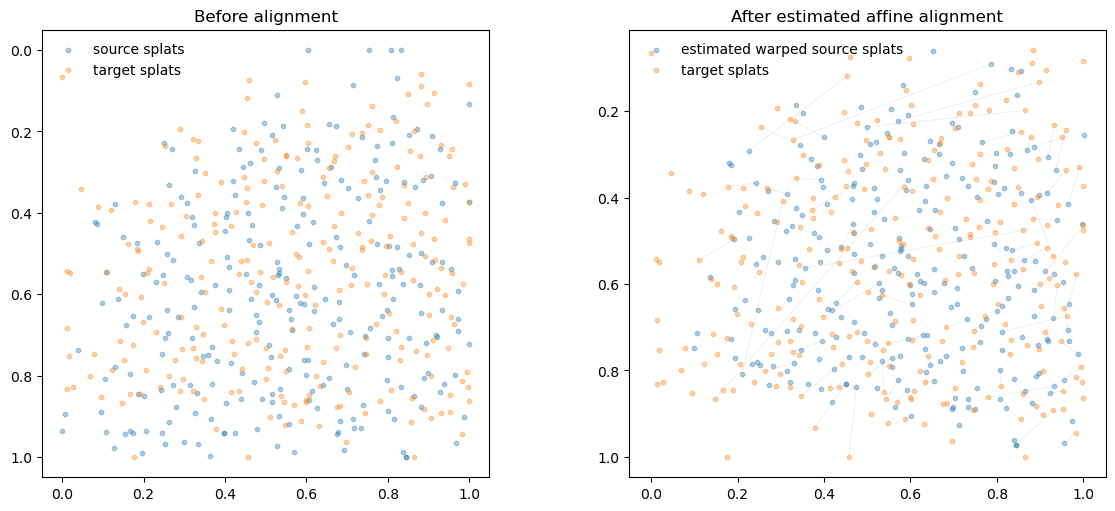

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

axes[0].scatter(source_means[:, 0], source_means[:, 1], s=10, alpha=0.35, color='tab:blue', label='source splats')
axes[0].scatter(target_means[:, 0], target_means[:, 1], s=10, alpha=0.35, color='tab:orange', label='target splats')
axes[0].invert_yaxis()
axes[0].set_aspect('equal')
axes[0].set_title('Before alignment')
axes[0].legend(frameon=False, loc='best')

warped_source_means = source_means @ est_linear.T + est_offset
axes[1].scatter(warped_source_means[:, 0], warped_source_means[:, 1], s=10, alpha=0.35, color='tab:blue', label='estimated warped source splats')
axes[1].scatter(target_means[:, 0], target_means[:, 1], s=10, alpha=0.35, color='tab:orange', label='target splats')
axes[1].plot(np.stack([warped_source_means[source_match_idx, 0], target_means[target_match_idx, 0]], axis=0), np.stack([warped_source_means[source_match_idx, 1], target_means[target_match_idx, 1]], axis=0), color='gray', alpha=0.15, linewidth=0.6)
axes[1].invert_yaxis()
axes[1].set_aspect('equal')
axes[1].set_title('After estimated affine alignment')
axes[1].legend(frameon=False, loc='best')

plt.show()


## Expression Drift Recovery From Matched Splats

Estimate a simple per-gene log-bias from matched splat compositions, then test whether correcting the target splat programs improves matched source-target cosine.


In [11]:
eps = 1e-8
source_pair_comp = source_comp[source_match_idx].numpy()
target_pair_comp = target_comp[target_match_idx].numpy()
pair_log_ratio = np.log(target_pair_comp + eps) - np.log(source_pair_comp + eps)
weighted_log_ratio = (pair_log_ratio * match_scores[:, None]).sum(axis=0) / np.clip(match_scores.sum(), 1e-8, None)
weighted_log_ratio_centered = weighted_log_ratio - weighted_log_ratio.mean()
true_log_bias_np = true_log_bias.detach().cpu().numpy()
true_log_bias_centered = true_log_bias_np - true_log_bias_np.mean()

drift_corr = float(np.corrcoef(weighted_log_ratio_centered, true_log_bias_centered)[0, 1])

target_comp_corrected = target_comp.numpy() * np.exp(-weighted_log_ratio_centered)[None, :]
target_comp_corrected = target_comp_corrected / np.clip(target_comp_corrected.sum(axis=1, keepdims=True), 1e-8, None)

before_pair_cos = np.sum(source_pair_comp * target_pair_comp, axis=1) / (
    np.linalg.norm(source_pair_comp, axis=1) * np.linalg.norm(target_pair_comp, axis=1) + eps
)
after_pair_cos = np.sum(source_pair_comp * target_comp_corrected[target_match_idx], axis=1) / (
    np.linalg.norm(source_pair_comp, axis=1) * np.linalg.norm(target_comp_corrected[target_match_idx], axis=1) + eps
)

drift_gene_names_full = base_drift_gene_names + region_drift_gene_names_a + region_drift_gene_names_b
recovered_bias_rank = np.argsort(-np.abs(weighted_log_ratio_centered))[:12]
recovered_bias_genes = [str(gene_names[int(i)]) for i in recovered_bias_rank.tolist()]

drift_recovery_summary = {
    'drift_bias_correlation_all_genes': drift_corr,
    'mean_matched_pair_cosine_before': float(np.mean(before_pair_cos)),
    'mean_matched_pair_cosine_after': float(np.mean(after_pair_cos)),
    'true_drift_genes': drift_gene_names_full,
    'top_recovered_bias_genes': recovered_bias_genes,
}
print('Splat drift recovery summary')
print(format_for_display(drift_recovery_summary))



Splat drift recovery summary
{'drift_bias_correlation_all_genes': 0.4406, 'mean_matched_pair_cosine_before': 0.9703, 'mean_matched_pair_cosine_after': 0.9633, 'true_drift_genes': ['Zfp536', 'Gng12', 'Clmn', 'Rab3b', 'Gad2', 'Cabp7', 'Prdm8', 'Nwd2', 'Bhlhe40', 'Necab1', 'Grik3', 'Slc17a6', 'Vat1l', 'Satb2', 'Ppp1r1b', 'Nell1', 'Pvalb', 'Gad1', 'Ndst3', 'Dkk3', 'Syndig1', 'Tle4', 'Arc', 'Car4', 'Igfbp5', 'Cdh13', 'Prox1', 'Bdnf', 'Mapk4', 'Rprm', 'Dner', 'Rorb', 'Ly6a', 'Aqp4', 'Fn1', 'Rims3', 'Pdzrn3', 'Ntsr2', 'Fhod3', 'Cpne4', 'Pde7b', 'Gfap', 'Tmem132d', 'Neto2', 'Slc17a7', 'Meis2', 'Bhlhe22', 'Pdgfra', 'Slit2', 'Nrn1', 'Lamp5', 'Sipa1l3', 'Neurod6', 'Parm1', 'Dpy19l1', 'Calb1', 'Cux2', 'Bcl11b', 'Rmst', 'Sox11', 'Opalin', 'Sorcs3', 'Plcxd3', 'Fezf2'], 'top_recovered_bias_genes': ['Pln', 'Sema5b', 'Fgd5', 'Plcxd3', 'Cplx3', 'Gad2', 'Fezf2', 'Fn1', 'Myl4', 'Cbln1', 'Zfp536', 'Opalin']}


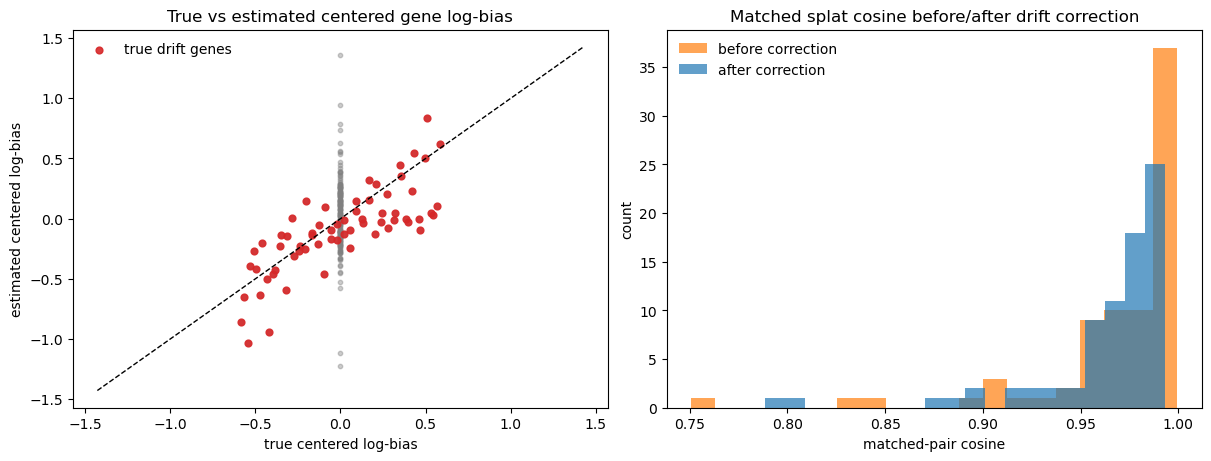

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

axes[0].scatter(true_log_bias_centered, weighted_log_ratio_centered, s=10, alpha=0.4, color='gray')
drift_gene_idx_all = torch.cat([base_gene_idx, region_gene_idx]) if len(region_gene_idx) > 0 else base_gene_idx
axes[0].scatter(true_log_bias_centered[drift_gene_idx_all.detach().cpu().numpy()], weighted_log_ratio_centered[drift_gene_idx_all.detach().cpu().numpy()], s=24, alpha=0.9, color='tab:red', label='true drift genes')
lim = max(np.abs(true_log_bias_centered).max(), np.abs(weighted_log_ratio_centered).max()) * 1.05
axes[0].plot([-lim, lim], [-lim, lim], linestyle='--', color='black', linewidth=1)
axes[0].set_title('True vs estimated centered gene log-bias')
axes[0].set_xlabel('true centered log-bias')
axes[0].set_ylabel('estimated centered log-bias')
axes[0].legend(frameon=False, loc='best')

axes[1].hist(before_pair_cos, bins=20, alpha=0.7, label='before correction', color='tab:orange')
axes[1].hist(after_pair_cos, bins=20, alpha=0.7, label='after correction', color='tab:blue')
axes[1].set_title('Matched splat cosine before/after drift correction')
axes[1].set_xlabel('matched-pair cosine')
axes[1].set_ylabel('count')
axes[1].legend(frameon=False, loc='best')

plt.show()



## Family-Level Drift Recovery

The harder pseudo-batch includes local and region-specific drift, so a single global correction vector is too restrictive. This section clusters matched source splats into program families, estimates one drift vector per family, and checks whether family-conditioned correction improves matched-pair agreement beyond the global correction.


Family-level splat drift recovery summary
{'n_match_families': 28, 'n_valid_match_families': 11, 'family_cosine_threshold': 0.8, 'min_family_matches': 3, 'drift_bias_correlation_family_conditioned': 0.4406, 'mean_matched_pair_cosine_before': 0.9703, 'mean_matched_pair_cosine_after_global': 0.9633, 'mean_matched_pair_cosine_after_family': 0.9716}


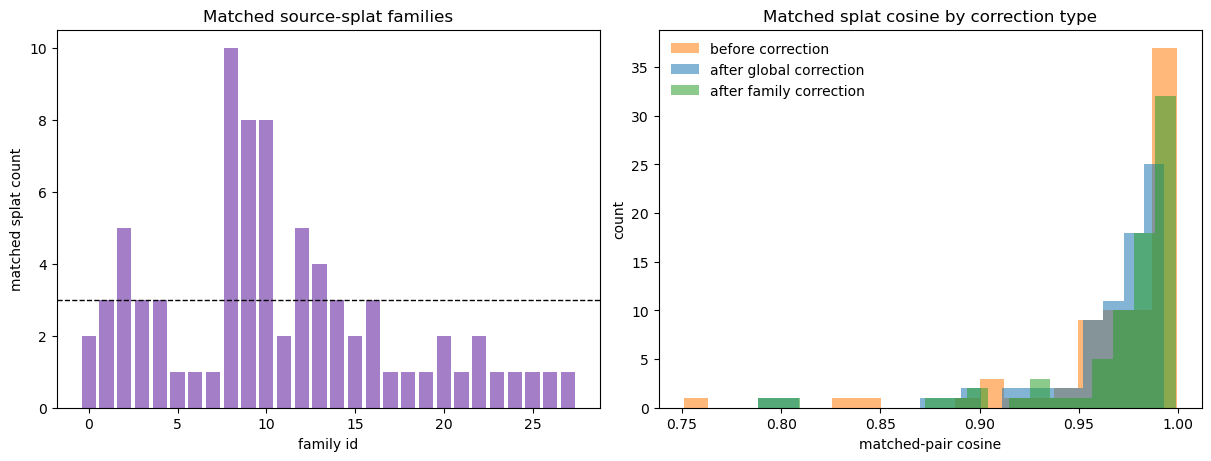

In [13]:
family_cosine_threshold = 0.8
min_family_matches = 3

source_match_comp = source_comp[source_match_idx].numpy()
source_match_comp_norm = source_match_comp / np.clip(np.linalg.norm(source_match_comp, axis=1, keepdims=True), 1e-8, None)
source_match_pairwise = source_match_comp_norm @ source_match_comp_norm.T

remaining = list(range(len(source_match_idx)))
match_families_local = []
while remaining:
    seed_local = remaining[0]
    sim = source_match_pairwise[seed_local]
    family_local = [idx for idx in remaining if sim[idx] >= family_cosine_threshold]
    match_families_local.append(family_local)
    remaining = [idx for idx in remaining if idx not in family_local]

family_records = []
source_match_family = np.full(len(source_match_idx), -1, dtype=np.int64)
family_prototypes = []
family_log_biases = []
global_log_bias_vector = weighted_log_ratio_centered.copy()

for family_id, family_local in enumerate(match_families_local):
    family_scores = match_scores[family_local]
    family_source = source_pair_comp[family_local]
    family_target = target_pair_comp[family_local]
    family_proto = family_source.mean(axis=0)
    family_proto = family_proto / np.clip(np.linalg.norm(family_proto), 1e-8, None)
    family_log_ratio = np.log(family_target + eps) - np.log(family_source + eps)
    family_weighted = (family_log_ratio * family_scores[:, None]).sum(axis=0) / np.clip(family_scores.sum(), 1e-8, None)
    family_weighted_centered = family_weighted - family_weighted.mean()
    for local_idx in family_local:
        source_match_family[local_idx] = family_id
    family_prototypes.append(family_proto)
    family_log_biases.append(family_weighted_centered)
    family_records.append({
        'family_id': int(family_id),
        'n_matches': int(len(family_local)),
        'median_match_cosine': float(np.median(family_scores)),
    })

family_prototypes = np.stack(family_prototypes, axis=0)
family_log_biases = np.stack(family_log_biases, axis=0)
family_valid_mask = np.array([rec['n_matches'] >= min_family_matches for rec in family_records], dtype=bool)

source_comp_np = source_comp.numpy()
target_comp_np = target_comp.numpy()
target_comp_norm_np = target_comp_np / np.clip(np.linalg.norm(target_comp_np, axis=1, keepdims=True), 1e-8, None)
family_proto_sim_target = target_comp_norm_np @ family_prototypes.T
target_family_assign = family_proto_sim_target.argmax(axis=1)

# Use family-specific correction when the family has enough matched pairs; otherwise fall back to the global bias.
target_comp_family_corrected = target_comp_np.copy()
for family_id in range(len(family_records)):
    mask = target_family_assign == family_id
    if not np.any(mask):
        continue
    bias_vec = family_log_biases[family_id] if family_valid_mask[family_id] else global_log_bias_vector
    corrected = target_comp_family_corrected[mask] * np.exp(-bias_vec)[None, :]
    corrected = corrected / np.clip(corrected.sum(axis=1, keepdims=True), 1e-8, None)
    target_comp_family_corrected[mask] = corrected

after_family_pair_cos = np.sum(source_pair_comp * target_comp_family_corrected[target_match_idx], axis=1) / (
    np.linalg.norm(source_pair_comp, axis=1) * np.linalg.norm(target_comp_family_corrected[target_match_idx], axis=1) + eps
)

family_specific_bias_for_matches = family_log_biases[source_match_family]
match_specific_bias_estimate = (family_specific_bias_for_matches * match_scores[:, None]).sum(axis=0) / np.clip(match_scores.sum(), 1e-8, None)
match_specific_bias_estimate_centered = match_specific_bias_estimate - match_specific_bias_estimate.mean()
family_drift_corr = float(np.corrcoef(match_specific_bias_estimate_centered, true_log_bias_centered)[0, 1])

family_drift_summary = {
    'n_match_families': int(len(family_records)),
    'n_valid_match_families': int(family_valid_mask.sum()),
    'family_cosine_threshold': float(family_cosine_threshold),
    'min_family_matches': int(min_family_matches),
    'drift_bias_correlation_family_conditioned': family_drift_corr,
    'mean_matched_pair_cosine_before': float(np.mean(before_pair_cos)),
    'mean_matched_pair_cosine_after_global': float(np.mean(after_pair_cos)),
    'mean_matched_pair_cosine_after_family': float(np.mean(after_family_pair_cos)),
}
print('Family-level splat drift recovery summary')
print(format_for_display(family_drift_summary))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

family_sizes = [rec['n_matches'] for rec in family_records]
axes[0].bar(np.arange(len(family_sizes)), family_sizes, color='tab:purple', alpha=0.85)
axes[0].axhline(min_family_matches, color='black', linestyle='--', linewidth=1)
axes[0].set_title('Matched source-splat families')
axes[0].set_xlabel('family id')
axes[0].set_ylabel('matched splat count')

axes[1].hist(before_pair_cos, bins=20, alpha=0.55, label='before correction', color='tab:orange')
axes[1].hist(after_pair_cos, bins=20, alpha=0.55, label='after global correction', color='tab:blue')
axes[1].hist(after_family_pair_cos, bins=20, alpha=0.55, label='after family correction', color='tab:green')
axes[1].set_title('Matched splat cosine by correction type')
axes[1].set_xlabel('matched-pair cosine')
axes[1].set_ylabel('count')
axes[1].legend(frameon=False, loc='best')

plt.show()





## Naive Spatial-Bin Correction Baseline

Estimate a rough affine alignment from the two cell clouds without splats, then compute correction vectors from overlapping coarse spatial bins. This is a fairer non-splat baseline because it does not use exact cell pairing to estimate correction. True pairing is used only afterward for evaluation in this synthetic setup.


Naive spatial-bin correction summary
{'rough_alignment': {'n_overlap_bins': 341, 'grid_size': 24, 'min_bin_cells': 8, 'rough_linear_error_l2': 0.3369, 'rough_offset_error_l2': 0.2216}, 'all_genes': {'drift_bias_correlation_global_bin': 0.8393, 'mean_cosine_before': 0.9129, 'mean_cosine_after_global_bin': 0.9411, 'mean_cosine_after_local_bin': 0.7714, 'mean_mae_before': 0.0009037, 'mean_mae_after_global_bin': 0.0009429, 'mean_mae_after_local_bin': 0.002324}, 'drift_genes_only': {'mean_cosine_before': 0.9014, 'mean_cosine_after_global_bin': 0.9251, 'mean_cosine_after_local_bin': 0.8067, 'mean_mae_before': 0.004891, 'mean_mae_after_global_bin': 0.00523, 'mean_mae_after_local_bin': 0.008269}}
Naive bin-vs-splat correction comparison
{'bin_global_all_genes_mean_cosine_after': 0.9411, 'bin_local_all_genes_mean_cosine_after': 0.7714, 'splat_global_all_genes_mean_cosine_after': 0.9633, 'splat_family_all_genes_mean_cosine_after': 0.9716, 'bin_global_drift_only_mean_cosine_after': 0.9251, 'bin_l

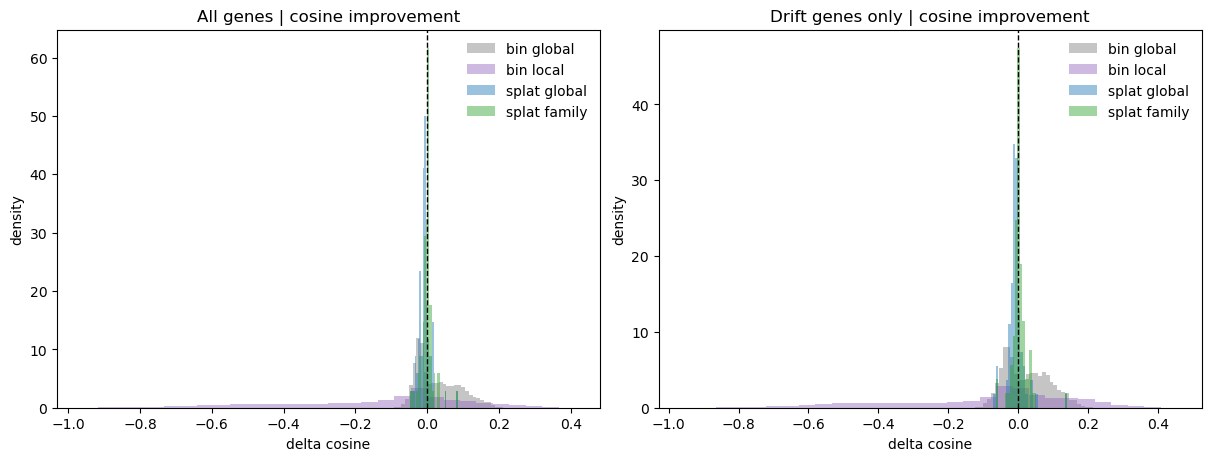

In [14]:
eps = 1e-8
baseline_bin_grid = 24
baseline_min_bin_cells = 8

drift_gene_idx_all = torch.cat([base_gene_idx, region_gene_idx]) if len(region_gene_idx) > 0 else base_gene_idx
drift_gene_idx_np = drift_gene_idx_all.detach().cpu().numpy()

source_xy_np = source_xy.detach().cpu().numpy()
target_xy_np = target_xy.detach().cpu().numpy()
source_cell_comp = source_profiles.detach().cpu().numpy()
target_cell_comp = (target_counts / target_counts.sum(dim=1, keepdim=True).clamp_min(1.0)).detach().cpu().numpy()


def estimate_rough_affine_from_clouds(source_xy_np: np.ndarray, target_xy_np: np.ndarray):
    src_ctr = source_xy_np.mean(axis=0)
    tgt_ctr = target_xy_np.mean(axis=0)
    src_centered = source_xy_np - src_ctr
    tgt_centered = target_xy_np - tgt_ctr

    src_cov = np.cov(src_centered.T)
    tgt_cov = np.cov(tgt_centered.T)
    src_vals, src_vecs = np.linalg.eigh(src_cov)
    tgt_vals, tgt_vecs = np.linalg.eigh(tgt_cov)
    src_order = np.argsort(src_vals)[::-1]
    tgt_order = np.argsort(tgt_vals)[::-1]
    src_vecs = src_vecs[:, src_order]
    tgt_vecs = tgt_vecs[:, tgt_order]
    src_vals = src_vals[src_order]
    tgt_vals = tgt_vals[tgt_order]

    if np.linalg.det(src_vecs) < 0:
        src_vecs[:, -1] *= -1
    if np.linalg.det(tgt_vecs) < 0:
        tgt_vecs[:, -1] *= -1

    scales = np.sqrt(np.clip(tgt_vals, 1e-8, None)) / np.sqrt(np.clip(src_vals, 1e-8, None))
    linear_t = src_vecs @ np.diag(scales) @ tgt_vecs.T
    linear = linear_t.T
    offset = tgt_ctr - src_ctr @ linear.T
    return linear.astype(np.float32), offset.astype(np.float32)


def assign_bin_ids(xy_np: np.ndarray, grid_size: int):
    clipped = np.clip(xy_np, 0.0, 0.999999)
    ij = np.floor(clipped * grid_size).astype(np.int64)
    return ij[:, 0] * grid_size + ij[:, 1], ij


rough_linear, rough_offset = estimate_rough_affine_from_clouds(source_xy_np, target_xy_np)
source_xy_rough = source_xy_np @ rough_linear.T + rough_offset

source_bin_ids, source_bin_ij = assign_bin_ids(source_xy_rough, baseline_bin_grid)
target_bin_ids, target_bin_ij = assign_bin_ids(target_xy_np, baseline_bin_grid)

num_bins = baseline_bin_grid * baseline_bin_grid
source_bin_sum = np.zeros((num_bins, source_cell_comp.shape[1]), dtype=np.float64)
target_bin_sum = np.zeros((num_bins, target_cell_comp.shape[1]), dtype=np.float64)
source_bin_count = np.bincount(source_bin_ids, minlength=num_bins)
target_bin_count = np.bincount(target_bin_ids, minlength=num_bins)
np.add.at(source_bin_sum, source_bin_ids, source_cell_comp)
np.add.at(target_bin_sum, target_bin_ids, target_cell_comp)

source_bin_mean = source_bin_sum / np.clip(source_bin_count[:, None], 1.0, None)
target_bin_mean = target_bin_sum / np.clip(target_bin_count[:, None], 1.0, None)
overlap_bin_mask = (source_bin_count >= baseline_min_bin_cells) & (target_bin_count >= baseline_min_bin_cells)
overlap_bins = np.flatnonzero(overlap_bin_mask)
if len(overlap_bins) == 0:
    raise RuntimeError('No overlapping spatial bins found for naive baseline; lower baseline_min_bin_cells or inspect rough alignment.')

bin_log_ratio = np.log(target_bin_mean[overlap_bins] + eps) - np.log(source_bin_mean[overlap_bins] + eps)
global_bin_bias = bin_log_ratio.mean(axis=0)
global_bin_bias_centered = global_bin_bias - global_bin_bias.mean()

local_bin_bias = np.zeros((num_bins, source_cell_comp.shape[1]), dtype=np.float64)
local_bin_bias[:] = global_bin_bias_centered[None, :]
local_bin_bias[overlap_bins] = bin_log_ratio - bin_log_ratio.mean(axis=1, keepdims=True)

# Apply non-splat corrections to target cells by their target-space coarse bin.
target_cell_comp_global = target_cell_comp * np.exp(-global_bin_bias_centered)[None, :]
target_cell_comp_global = target_cell_comp_global / np.clip(target_cell_comp_global.sum(axis=1, keepdims=True), 1e-8, None)

target_cell_comp_local = target_cell_comp * np.exp(-local_bin_bias[target_bin_ids])
target_cell_comp_local = target_cell_comp_local / np.clip(target_cell_comp_local.sum(axis=1, keepdims=True), 1e-8, None)

# Evaluate using the known synthetic pairing only after correction is estimated.
def row_cos(a: np.ndarray, b: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    return np.sum(a * b, axis=1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + eps)

def row_mae(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    return np.mean(np.abs(a - b), axis=1)

cell_before_cos = row_cos(source_cell_comp, target_cell_comp)
cell_after_global_cos = row_cos(source_cell_comp, target_cell_comp_global)
cell_after_local_cos = row_cos(source_cell_comp, target_cell_comp_local)

cell_before_mae = row_mae(source_cell_comp, target_cell_comp)
cell_after_global_mae = row_mae(source_cell_comp, target_cell_comp_global)
cell_after_local_mae = row_mae(source_cell_comp, target_cell_comp_local)

source_cell_comp_drift = source_cell_comp[:, drift_gene_idx_np]
target_cell_comp_drift = target_cell_comp[:, drift_gene_idx_np]
target_cell_comp_global_drift = target_cell_comp_global[:, drift_gene_idx_np]
target_cell_comp_local_drift = target_cell_comp_local[:, drift_gene_idx_np]

source_cell_comp_drift = source_cell_comp_drift / np.clip(source_cell_comp_drift.sum(axis=1, keepdims=True), 1e-8, None)
target_cell_comp_drift = target_cell_comp_drift / np.clip(target_cell_comp_drift.sum(axis=1, keepdims=True), 1e-8, None)
target_cell_comp_global_drift = target_cell_comp_global_drift / np.clip(target_cell_comp_global_drift.sum(axis=1, keepdims=True), 1e-8, None)
target_cell_comp_local_drift = target_cell_comp_local_drift / np.clip(target_cell_comp_local_drift.sum(axis=1, keepdims=True), 1e-8, None)

cell_before_cos_drift = row_cos(source_cell_comp_drift, target_cell_comp_drift)
cell_after_global_cos_drift = row_cos(source_cell_comp_drift, target_cell_comp_global_drift)
cell_after_local_cos_drift = row_cos(source_cell_comp_drift, target_cell_comp_local_drift)

cell_before_mae_drift = row_mae(source_cell_comp_drift, target_cell_comp_drift)
cell_after_global_mae_drift = row_mae(source_cell_comp_drift, target_cell_comp_global_drift)
cell_after_local_mae_drift = row_mae(source_cell_comp_drift, target_cell_comp_local_drift)

cell_global_corr = float(np.corrcoef(global_bin_bias_centered, true_log_bias_centered)[0, 1])

cell_baseline_summary = {
    'rough_alignment': {
        'n_overlap_bins': int(len(overlap_bins)),
        'grid_size': int(baseline_bin_grid),
        'min_bin_cells': int(baseline_min_bin_cells),
        'rough_linear_error_l2': float(np.linalg.norm(rough_linear - true_linear_np)),
        'rough_offset_error_l2': float(np.linalg.norm(rough_offset - true_offset_np)),
    },
    'all_genes': {
        'drift_bias_correlation_global_bin': cell_global_corr,
        'mean_cosine_before': float(np.mean(cell_before_cos)),
        'mean_cosine_after_global_bin': float(np.mean(cell_after_global_cos)),
        'mean_cosine_after_local_bin': float(np.mean(cell_after_local_cos)),
        'mean_mae_before': float(np.mean(cell_before_mae)),
        'mean_mae_after_global_bin': float(np.mean(cell_after_global_mae)),
        'mean_mae_after_local_bin': float(np.mean(cell_after_local_mae)),
    },
    'drift_genes_only': {
        'mean_cosine_before': float(np.mean(cell_before_cos_drift)),
        'mean_cosine_after_global_bin': float(np.mean(cell_after_global_cos_drift)),
        'mean_cosine_after_local_bin': float(np.mean(cell_after_local_cos_drift)),
        'mean_mae_before': float(np.mean(cell_before_mae_drift)),
        'mean_mae_after_global_bin': float(np.mean(cell_after_global_mae_drift)),
        'mean_mae_after_local_bin': float(np.mean(cell_after_local_mae_drift)),
    },
}
print('Naive spatial-bin correction summary')
print(format_for_display(cell_baseline_summary))


# Local splat metrics for fair comparison inside this baseline cell.
source_pair_comp_local = source_pair_comp
target_pair_comp_local = target_pair_comp
target_pair_comp_global_local = target_comp_corrected[target_match_idx]
target_pair_comp_family_local = target_comp_family_corrected[target_match_idx]

splat_before_cos_local = row_cos(source_pair_comp_local, target_pair_comp_local)
splat_after_global_cos_local = row_cos(source_pair_comp_local, target_pair_comp_global_local)
splat_after_family_cos_local = row_cos(source_pair_comp_local, target_pair_comp_family_local)

source_pair_comp_drift_local = source_pair_comp_local[:, drift_gene_idx_np]
target_pair_comp_drift_local = target_pair_comp_local[:, drift_gene_idx_np]
target_pair_comp_global_drift_local = target_pair_comp_global_local[:, drift_gene_idx_np]
target_pair_comp_family_drift_local = target_pair_comp_family_local[:, drift_gene_idx_np]

source_pair_comp_drift_local = source_pair_comp_drift_local / np.clip(source_pair_comp_drift_local.sum(axis=1, keepdims=True), 1e-8, None)
target_pair_comp_drift_local = target_pair_comp_drift_local / np.clip(target_pair_comp_drift_local.sum(axis=1, keepdims=True), 1e-8, None)
target_pair_comp_global_drift_local = target_pair_comp_global_drift_local / np.clip(target_pair_comp_global_drift_local.sum(axis=1, keepdims=True), 1e-8, None)
target_pair_comp_family_drift_local = target_pair_comp_family_drift_local / np.clip(target_pair_comp_family_drift_local.sum(axis=1, keepdims=True), 1e-8, None)

splat_before_cos_drift_local = row_cos(source_pair_comp_drift_local, target_pair_comp_drift_local)
splat_after_global_cos_drift_local = row_cos(source_pair_comp_drift_local, target_pair_comp_global_drift_local)
splat_after_family_cos_drift_local = row_cos(source_pair_comp_drift_local, target_pair_comp_family_drift_local)

cell_global_improvement = cell_after_global_cos - cell_before_cos
cell_local_improvement = cell_after_local_cos - cell_before_cos
cell_global_improvement_drift = cell_after_global_cos_drift - cell_before_cos_drift
cell_local_improvement_drift = cell_after_local_cos_drift - cell_before_cos_drift
global_cos_improvement_local = splat_after_global_cos_local - splat_before_cos_local
family_cos_improvement_local = splat_after_family_cos_local - splat_before_cos_local
global_cos_improvement_drift_local = splat_after_global_cos_drift_local - splat_before_cos_drift_local
family_cos_improvement_drift_local = splat_after_family_cos_drift_local - splat_before_cos_drift_local

comparison_summary = {
    'bin_global_all_genes_mean_cosine_after': float(np.mean(cell_after_global_cos)),
    'bin_local_all_genes_mean_cosine_after': float(np.mean(cell_after_local_cos)),
    'splat_global_all_genes_mean_cosine_after': float(np.mean(splat_after_global_cos_local)),
    'splat_family_all_genes_mean_cosine_after': float(np.mean(splat_after_family_cos_local)),
    'bin_global_drift_only_mean_cosine_after': float(np.mean(cell_after_global_cos_drift)),
    'bin_local_drift_only_mean_cosine_after': float(np.mean(cell_after_local_cos_drift)),
    'splat_global_drift_only_mean_cosine_after': float(np.mean(splat_after_global_cos_drift_local)),
    'splat_family_drift_only_mean_cosine_after': float(np.mean(splat_after_family_cos_drift_local)),
}
print('Naive bin-vs-splat correction comparison')
print(format_for_display(comparison_summary))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].hist(cell_global_improvement, bins=30, density=True, alpha=0.45, label='bin global', color='tab:gray')
axes[0].hist(cell_local_improvement, bins=30, density=True, alpha=0.45, label='bin local', color='tab:purple')
axes[0].hist(global_cos_improvement_local, bins=30, density=True, alpha=0.45, label='splat global', color='tab:blue')
axes[0].hist(family_cos_improvement_local, bins=30, density=True, alpha=0.45, label='splat family', color='tab:green')
axes[0].axvline(0.0, color='black', linestyle='--', linewidth=1)
axes[0].set_title('All genes | cosine improvement')
axes[0].set_xlabel('delta cosine')
axes[0].set_ylabel('density')
axes[0].legend(frameon=False, loc='best')

axes[1].hist(cell_global_improvement_drift, bins=30, density=True, alpha=0.45, label='bin global', color='tab:gray')
axes[1].hist(cell_local_improvement_drift, bins=30, density=True, alpha=0.45, label='bin local', color='tab:purple')
axes[1].hist(global_cos_improvement_drift_local, bins=30, density=True, alpha=0.45, label='splat global', color='tab:blue')
axes[1].hist(family_cos_improvement_drift_local, bins=30, density=True, alpha=0.45, label='splat family', color='tab:green')
axes[1].axvline(0.0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Drift genes only | cosine improvement')
axes[1].set_xlabel('delta cosine')
axes[1].set_ylabel('density')
axes[1].legend(frameon=False, loc='best')
plt.show()



## Correction Sensitivity Diagnostics

Full-vector cosine over all genes can hide meaningful correction because many genes are unchanged. This section measures improvement on the injected drift-gene subset and shows per-pair improvement directly.


Correction sensitivity summary
{'all_genes': {'mean_cosine_before': 0.9703, 'mean_cosine_after_global': 0.9633, 'mean_cosine_after_family': 0.9716, 'mean_global_cosine_improvement': -0.006917, 'mean_family_cosine_improvement': 0.001384}, 'drift_genes_only': {'n_drift_genes': 64, 'mean_cosine_before': 0.9681, 'mean_cosine_after_global': 0.9622, 'mean_cosine_after_family': 0.9722, 'mean_mae_before': 0.003596, 'mean_mae_after_global': 0.003992, 'mean_mae_after_family': 0.003253, 'mean_global_cosine_improvement': -0.005905, 'mean_family_cosine_improvement': 0.004091, 'mean_global_mae_reduction': -0.000396, 'mean_family_mae_reduction': 0.0003423}}


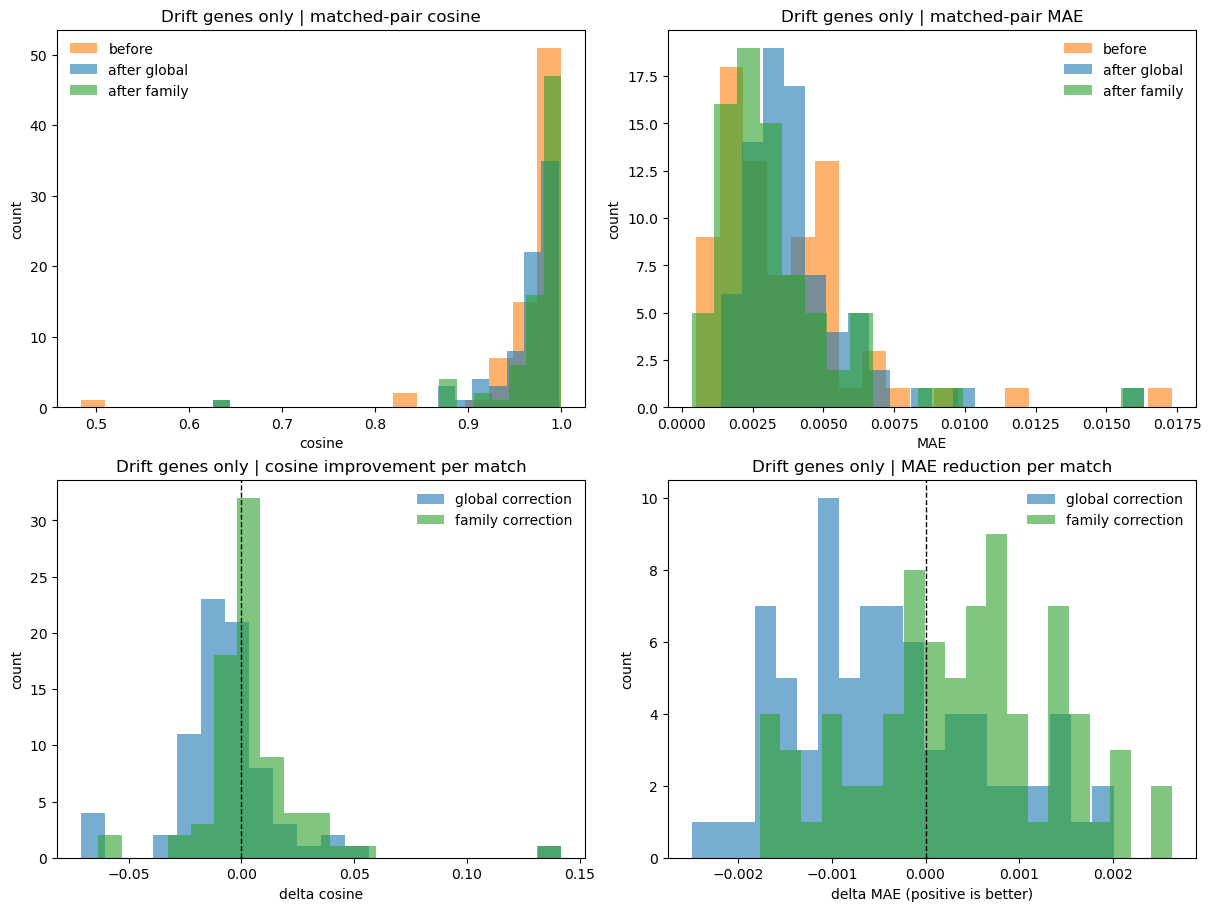

In [15]:
drift_gene_idx_all = torch.cat([base_gene_idx, region_gene_idx]) if len(region_gene_idx) > 0 else base_gene_idx
drift_gene_idx_np = drift_gene_idx_all.detach().cpu().numpy()

source_pair_comp_drift = source_pair_comp[:, drift_gene_idx_np]
target_pair_comp_drift = target_pair_comp[:, drift_gene_idx_np]
target_pair_comp_global_drift = target_comp_corrected[target_match_idx][:, drift_gene_idx_np]
target_pair_comp_family_drift = target_comp_family_corrected[target_match_idx][:, drift_gene_idx_np]

# Renormalize within the perturbed-gene subset before computing subset-specific metrics.
def renorm_rows(x: np.ndarray) -> np.ndarray:
    return x / np.clip(x.sum(axis=1, keepdims=True), 1e-8, None)

source_pair_comp_drift = renorm_rows(source_pair_comp_drift)
target_pair_comp_drift = renorm_rows(target_pair_comp_drift)
target_pair_comp_global_drift = renorm_rows(target_pair_comp_global_drift)
target_pair_comp_family_drift = renorm_rows(target_pair_comp_family_drift)

def row_cos(a: np.ndarray, b: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    return np.sum(a * b, axis=1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + eps)

def row_mae(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    return np.mean(np.abs(a - b), axis=1)

before_pair_cos_drift = row_cos(source_pair_comp_drift, target_pair_comp_drift)
after_global_pair_cos_drift = row_cos(source_pair_comp_drift, target_pair_comp_global_drift)
after_family_pair_cos_drift = row_cos(source_pair_comp_drift, target_pair_comp_family_drift)

before_pair_mae_drift = row_mae(source_pair_comp_drift, target_pair_comp_drift)
after_global_pair_mae_drift = row_mae(source_pair_comp_drift, target_pair_comp_global_drift)
after_family_pair_mae_drift = row_mae(source_pair_comp_drift, target_pair_comp_family_drift)

global_cos_improvement = after_pair_cos - before_pair_cos
family_cos_improvement = after_family_pair_cos - before_pair_cos
global_cos_improvement_drift = after_global_pair_cos_drift - before_pair_cos_drift
family_cos_improvement_drift = after_family_pair_cos_drift - before_pair_cos_drift

global_mae_reduction_drift = before_pair_mae_drift - after_global_pair_mae_drift
family_mae_reduction_drift = before_pair_mae_drift - after_family_pair_mae_drift

sensitivity_summary = {
    'all_genes': {
        'mean_cosine_before': float(np.mean(before_pair_cos)),
        'mean_cosine_after_global': float(np.mean(after_pair_cos)),
        'mean_cosine_after_family': float(np.mean(after_family_pair_cos)),
        'mean_global_cosine_improvement': float(np.mean(global_cos_improvement)),
        'mean_family_cosine_improvement': float(np.mean(family_cos_improvement)),
    },
    'drift_genes_only': {
        'n_drift_genes': int(len(drift_gene_idx_np)),
        'mean_cosine_before': float(np.mean(before_pair_cos_drift)),
        'mean_cosine_after_global': float(np.mean(after_global_pair_cos_drift)),
        'mean_cosine_after_family': float(np.mean(after_family_pair_cos_drift)),
        'mean_mae_before': float(np.mean(before_pair_mae_drift)),
        'mean_mae_after_global': float(np.mean(after_global_pair_mae_drift)),
        'mean_mae_after_family': float(np.mean(after_family_pair_mae_drift)),
        'mean_global_cosine_improvement': float(np.mean(global_cos_improvement_drift)),
        'mean_family_cosine_improvement': float(np.mean(family_cos_improvement_drift)),
        'mean_global_mae_reduction': float(np.mean(global_mae_reduction_drift)),
        'mean_family_mae_reduction': float(np.mean(family_mae_reduction_drift)),
    },
}
print('Correction sensitivity summary')
print(format_for_display(sensitivity_summary))

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)

axes[0, 0].hist(before_pair_cos_drift, bins=20, alpha=0.6, label='before', color='tab:orange')
axes[0, 0].hist(after_global_pair_cos_drift, bins=20, alpha=0.6, label='after global', color='tab:blue')
axes[0, 0].hist(after_family_pair_cos_drift, bins=20, alpha=0.6, label='after family', color='tab:green')
axes[0, 0].set_title('Drift genes only | matched-pair cosine')
axes[0, 0].set_xlabel('cosine')
axes[0, 0].set_ylabel('count')
axes[0, 0].legend(frameon=False, loc='best')

axes[0, 1].hist(before_pair_mae_drift, bins=20, alpha=0.6, label='before', color='tab:orange')
axes[0, 1].hist(after_global_pair_mae_drift, bins=20, alpha=0.6, label='after global', color='tab:blue')
axes[0, 1].hist(after_family_pair_mae_drift, bins=20, alpha=0.6, label='after family', color='tab:green')
axes[0, 1].set_title('Drift genes only | matched-pair MAE')
axes[0, 1].set_xlabel('MAE')
axes[0, 1].set_ylabel('count')
axes[0, 1].legend(frameon=False, loc='best')

axes[1, 0].hist(global_cos_improvement_drift, bins=20, alpha=0.6, label='global correction', color='tab:blue')
axes[1, 0].hist(family_cos_improvement_drift, bins=20, alpha=0.6, label='family correction', color='tab:green')
axes[1, 0].axvline(0.0, color='black', linestyle='--', linewidth=1)
axes[1, 0].set_title('Drift genes only | cosine improvement per match')
axes[1, 0].set_xlabel('delta cosine')
axes[1, 0].set_ylabel('count')
axes[1, 0].legend(frameon=False, loc='best')

axes[1, 1].hist(global_mae_reduction_drift, bins=20, alpha=0.6, label='global correction', color='tab:blue')
axes[1, 1].hist(family_mae_reduction_drift, bins=20, alpha=0.6, label='family correction', color='tab:green')
axes[1, 1].axvline(0.0, color='black', linestyle='--', linewidth=1)
axes[1, 1].set_title('Drift genes only | MAE reduction per match')
axes[1, 1].set_xlabel('delta MAE (positive is better)')
axes[1, 1].set_ylabel('count')
axes[1, 1].legend(frameon=False, loc='best')

plt.show()


## Family-Colored Splat Overlays

Overlay the learned splats on the source and target pseudo-batches, scaling each splat by its learned geometry and coloring matched splats by the family assignments used in the family-level drift correction step.


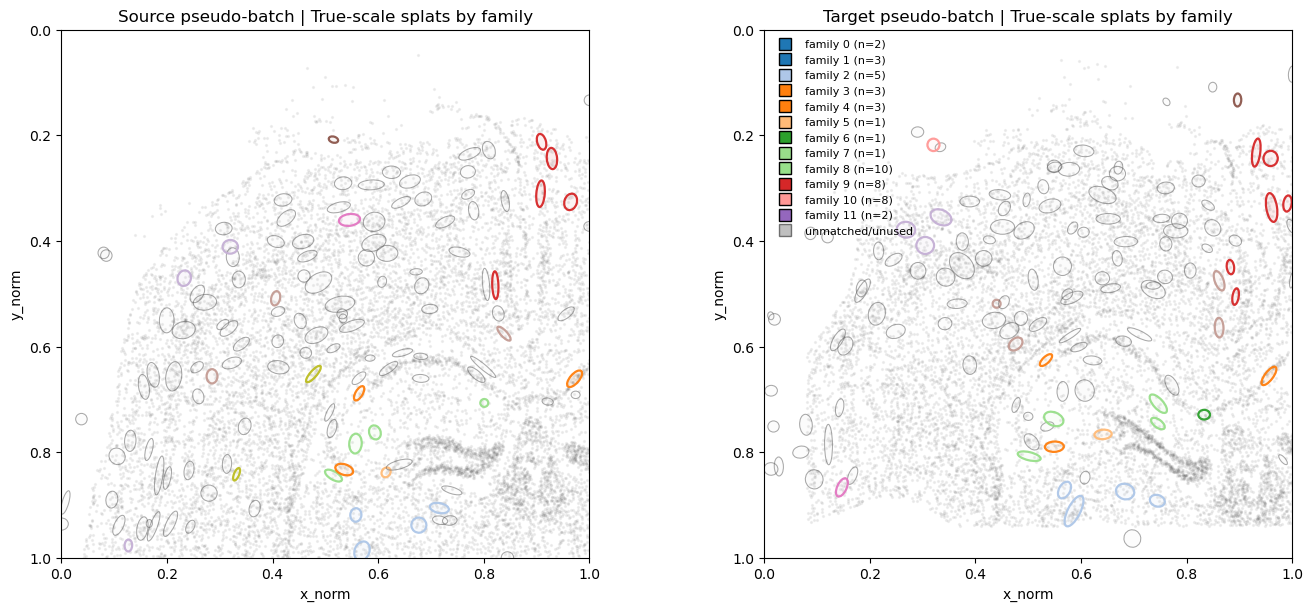

In [16]:
source_scales = np.exp(source_model.log_scales.detach().cpu().numpy())
target_scales = np.exp(target_model.log_scales.detach().cpu().numpy())
source_rot = source_model.rotation.detach().cpu().numpy().reshape(-1)
target_rot = target_model.rotation.detach().cpu().numpy().reshape(-1)

with torch.no_grad():
    source_weight_query_idx = torch.randperm(len(source_bundle['xy']), device=device)[:min(2048, len(source_bundle['xy']))]
    target_weight_query_idx = torch.randperm(len(target_bundle['xy']), device=device)[:min(2048, len(target_bundle['xy']))]
    source_mean_usage = compute_splat_weights(source_model, source_bundle['xy'][source_weight_query_idx]).mean(dim=0).detach().cpu().numpy()
    target_mean_usage = compute_splat_weights(target_model, target_bundle['xy'][target_weight_query_idx]).mean(dim=0).detach().cpu().numpy()

source_family_per_splat = np.full(source_model.num_splats, -1, dtype=np.int64)
for local_idx, splat_idx in enumerate(source_match_idx):
    source_family_per_splat[splat_idx] = source_match_family[local_idx]

target_family_per_splat = np.full(target_model.num_splats, -1, dtype=np.int64)
for local_idx, splat_idx in enumerate(target_match_idx):
    target_family_per_splat[splat_idx] = source_match_family[local_idx]

family_count = max(len(family_records), 1)
family_cmap = plt.get_cmap('tab20', family_count)
family_colors = [family_cmap(i) for i in range(family_count)]

source_amp = source_model.splat_amplitudes().detach().cpu().numpy().reshape(-1)
target_amp = target_model.splat_amplitudes().detach().cpu().numpy().reshape(-1)
source_active_mask = source_amp >= np.quantile(source_amp, 0.5)
target_active_mask = target_amp >= np.quantile(target_amp, 0.5)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

for ax, xy, means, scales, rot, fam_idx, mean_usage, active_mask, title in [
    (axes[0], source_xy_display.detach().cpu().numpy(), source_means, source_scales, source_rot, source_family_per_splat, source_mean_usage, source_active_mask, 'Source pseudo-batch | True-scale splats by family'),
    (axes[1], target_xy.detach().cpu().numpy(), target_means, target_scales, target_rot, target_family_per_splat, target_mean_usage, target_active_mask, 'Target pseudo-batch | True-scale splats by family'),
]:
    ax.scatter(xy[:, 0], xy[:, 1], s=2, alpha=0.05, color='black')
    draw_candidates = np.flatnonzero(active_mask)
    draw_order = draw_candidates[np.argsort(mean_usage[draw_candidates])]
    for splat_idx in draw_order:
        fam = fam_idx[splat_idx]
        color = family_colors[fam] if fam >= 0 else (0.7, 0.7, 0.7, 1.0)
        fill_alpha = float(np.clip(0.05 + 5.0 * mean_usage[splat_idx], 0.05, 0.45)) if fam >= 0 else float(np.clip(0.03 + 2.5 * mean_usage[splat_idx], 0.03, 0.12))
        ellipse = Ellipse(
            xy=means[splat_idx],
            width=2.0 * scales[splat_idx, 0],
            height=2.0 * scales[splat_idx, 1],
            angle=float(np.degrees(rot[splat_idx])),
            facecolor=color,
            edgecolor=(color if fam >= 0 else (0.45, 0.45, 0.45, 1.0)),
            linewidth=1.2 if fam >= 0 else 0.6,
            alpha=fill_alpha,
        )
        ax.add_patch(ellipse)
        outline = Ellipse(
            xy=means[splat_idx],
            width=2.0 * scales[splat_idx, 0],
            height=2.0 * scales[splat_idx, 1],
            angle=float(np.degrees(rot[splat_idx])),
            facecolor='none',
            edgecolor=(color if fam >= 0 else (0.35, 0.35, 0.35, 1.0)),
            linewidth=1.6 if fam >= 0 else 0.75,
            alpha=0.95 if fam >= 0 else 0.5,
        )
        ax.add_patch(outline)
    ax.invert_yaxis()
    ax.set_aspect('equal')
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)
    ax.set_title(title)
    ax.set_xlabel('x_norm')
    ax.set_ylabel('y_norm')

legend_handles = []
for family_id, rec in enumerate(family_records[:min(len(family_records), 12)]):
    legend_handles.append(plt.Line2D([0], [0], marker='s', color='none', markerfacecolor=family_colors[family_id], markersize=8, label=f"family {family_id} (n={rec['n_matches']})"))
legend_handles.append(plt.Line2D([0], [0], marker='s', color='none', markerfacecolor='gray', alpha=0.5, markersize=8, label='unmatched/unused'))
axes[1].legend(handles=legend_handles, frameon=False, loc='best', fontsize=8)

plt.show()



